# RateBeer: predicting a review's `overall` score

Goal: predict `overall` (out of 20) for a review before it is written, using the beer, its brewer, style, ABV, the reviewer's past reviews and the date. The score of the model is the **RMSE**: the typical size of its error, in rating points.

Steps: load and clean the data, split it by time, look at a few charts, build features, tune LightGBM with a random search, and score the test set once.

In [1]:
import ast
import html
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import PredefinedSplit, RandomizedSearchCV

pd.set_option("display.width", 150)
sns.set_theme(style="whitegrid")

RAW_PATH = Path("ratebeer.json")
CACHE_PATH = Path("ratebeer.parquet")
SEED = 0

## 1. Load and clean

`ratebeer.json` is not valid JSON (each line is a Python dict), so it is parsed once and cached as `ratebeer.parquet`.

Cleaning:
- About 69k reviews are stored twice (the same review under two brewer IDs). One review is kept per beer and reviewer, preferring a re-posted review that starts with "UPDATED".
- An ABV of `-` means missing, so it becomes blank.
- Style names contain HTML codes, which are decoded.
- January 2012 is only a partial month, so it is dropped.

The four sub-scores (appearance, aroma, palate, taste) and the review text are written together with `overall`, so they are not used.

In [2]:
COLS = ["beer/beerId", "beer/brewerId", "beer/ABV", "beer/style", "review/overall",
        "review/time", "review/profileName", "review/text"]


def load_raw():
    if not CACHE_PATH.exists():
        # one python dict per line; skip blank lines and the empty {} record at the end
        with open(RAW_PATH, encoding="utf-8") as f:
            records = [r for r in map(ast.literal_eval, (l for l in f if l.strip())) if r]
        pd.DataFrame.from_records(records).to_parquet(CACHE_PATH, index=False)
    return pd.read_parquet(CACHE_PATH, columns=COLS)


def drop_repeat_reviews(raw):
    # one row per (beer, reviewer); prefer the review whose text starts with "UPDATED", else the first
    not_updated = ~raw["review/text"].str.startswith("UPDATED")
    return (raw.assign(not_updated=not_updated).sort_values("not_updated", kind="stable")
            .drop_duplicates(["beer/beerId", "review/profileName"]).sort_index())


def to_frame(raw):
    styles = {s: html.unescape(s) for s in raw["beer/style"].unique()}
    return pd.DataFrame({
        "beer_id": raw["beer/beerId"].astype("category"),
        "brewer_id": raw["beer/brewerId"].astype("category"),
        "abv": pd.to_numeric(raw["beer/ABV"], errors="coerce"),  # "-" becomes NaN
        "style": raw["beer/style"].map(styles).astype("category"),
        "reviewer": raw["review/profileName"].astype("category"),
        "time": pd.to_datetime(pd.to_numeric(raw["review/time"]), unit="s"),
        "overall": raw["review/overall"].str.split("/").str[0].astype(float),  # "14/20" -> 14
    })


raw = load_raw()
n_raw = len(raw)
n_dash = (raw["beer/ABV"] == "-").sum()
df = to_frame(drop_repeat_reviews(raw))
del raw
df = df[df["time"] < "2012-01-01"].sort_values("time", kind="stable").reset_index(drop=True)
print(f"{n_raw:,} raw reviews ({n_dash:,} with ABV '-', set to blank) -> {len(df):,} after cleaning ({df['time'].min().date()} to {df['time'].max().date()})")

2,924,163 raw reviews (138,637 with ABV '-', set to blank) -> 2,841,841 after cleaning (2000-04-12 to 2011-12-31)


## 2. Time split

The first 70% of reviews (by date) are for training (fit), the next 10% for validation, and the last 20% for testing. Cuts fall on whole dates, so a day is never split between sets.

In [3]:
def split_by_time(df, q_val=0.7, q_test=0.8):
    c_val, c_test = df["time"].iloc[int(q_val * len(df))], df["time"].iloc[int(q_test * len(df))]
    t = df["time"]
    return df[t <= c_val], df[(t > c_val) & (t <= c_test)], df[t > c_test]


fit, val, test = split_by_time(df)
del df
print(pd.DataFrame({
    "rows": [len(s) for s in (fit, val, test)],
    "first": [s["time"].min().date() for s in (fit, val, test)],
    "last": [s["time"].max().date() for s in (fit, val, test)],
}, index=["fit", "val", "test"]).to_string())

         rows       first        last
fit   1990014  2000-04-12  2009-12-15
val    283551  2009-12-16  2010-09-03
test   568276  2010-09-04  2011-12-31


## 3. A few charts

**Ratings are skewed high:** most reviews are 12 to 16 out of 20.

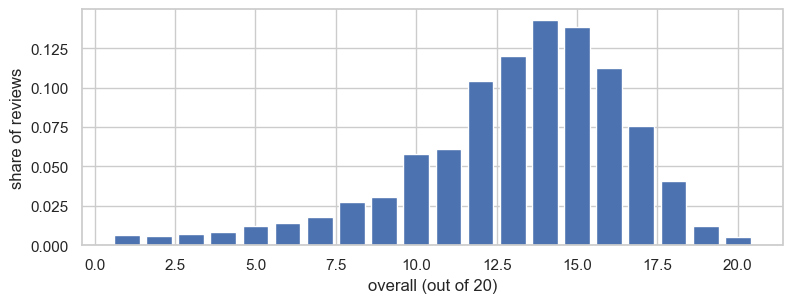

In [4]:
dist = fit["overall"].value_counts(normalize=True).sort_index()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(dist.index, dist.values)
ax.set(xlabel="overall (out of 20)", ylabel="share of reviews")
plt.tight_layout()

**Style matters a lot:** the average rating ranges from about 6 to about 16 across styles (styles with at least 1,000 reviews; 8 lowest and 8 highest shown).

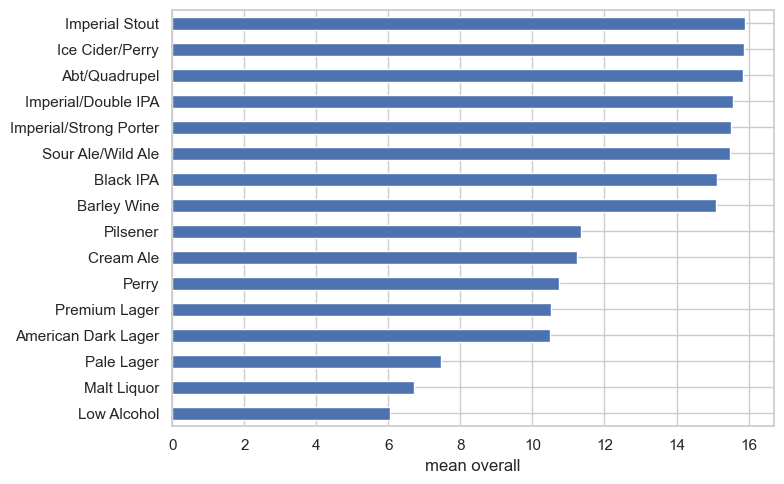

In [5]:
by_style = fit.groupby("style", observed=True)["overall"].agg(["mean", "size"])
by_style = by_style.loc[by_style["size"] >= 1000, "mean"].sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
pd.concat([by_style.head(8), by_style.tail(8)]).plot.barh(ax=ax)
ax.set(xlabel="mean overall", ylabel="")
plt.tight_layout()

**Stronger beers rate higher:** the average rating climbs with ABV, then levels off around 10%.

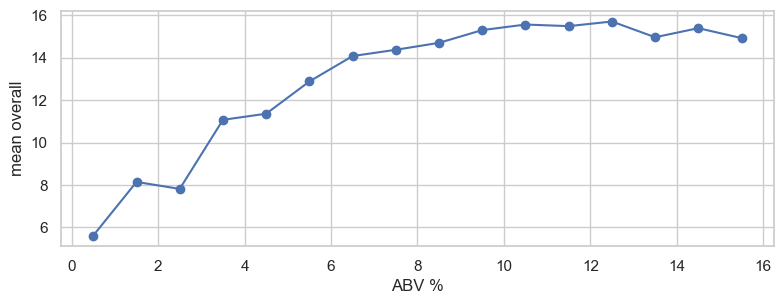

In [6]:
bins = pd.cut(fit["abv"], np.arange(0, 16.5, 1))
by_abv = fit.groupby(bins, observed=True)["overall"].agg(["mean", "size"])
by_abv = by_abv[by_abv["size"] >= 500]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(by_abv.index.map(lambda i: i.mid).astype(float), by_abv["mean"], marker="o")
ax.set(xlabel="ABV %", ylabel="mean overall")
plt.tight_layout()

## 4. Features

Inputs: `style`, `abv` (blank when missing), `month`, `dayofweek`, `days_since_start`, plus four **history** features:
- `beer_id_n`, `brewer_id_n`, `reviewer_n`: how many reviews the beer, brewer and reviewer had in the training data.
- `reviewer_mean`: the reviewer's average `overall` (how generous they are), pulled toward the overall average when they have few reviews.

For the training rows, a row's own rating must not leak into its own history features. So the training rows are split randomly into 10 folds, and each row's history is computed from the other 9 folds. Validation and test rows use all the training rows. A beer or reviewer with no history gets a count of 0 (and `reviewer_mean` falls back to the overall average).

In [7]:
KEYS = ["beer_id", "brewer_id", "reviewer"]


def history_features(train, others, k=10, m=5, seed=SEED):
    # count per key, plus a shrunk mean for the reviewer: (sum + m * global_mean) / (n + m)
    y = train["overall"].to_numpy(dtype=float)
    mu = y.mean()
    fold = np.random.default_rng(seed).integers(0, k, len(train))
    train_out, other_out = {}, [{} for _ in others]
    for key in KEYS:
        size = len(train[key].cat.categories) + 1  # extra slot for missing keys

        def codes(s):
            c = s.cat.codes.to_numpy().astype(np.int64)
            return np.where(c < 0, size - 1, c)

        code = codes(train[key])
        tot_n, tot_s = np.bincount(code, minlength=size), np.bincount(code, weights=y, minlength=size)
        # per-(key, fold) totals; subtracting a row's own fold leaves the out-of-fold stats
        cell = code * k + fold
        n = tot_n[code] - np.bincount(cell, minlength=size * k)[cell]
        s = tot_s[code] - np.bincount(cell, weights=y, minlength=size * k)[cell]
        train_out[f"{key}_n"] = n
        if key == "reviewer":
            train_out["reviewer_mean"] = (s + m * mu) / (n + m)
        for o, out in zip(others, other_out):
            c = codes(o[key])
            out[f"{key}_n"] = tot_n[c]
            if key == "reviewer":
                out["reviewer_mean"] = (tot_s[c] + m * mu) / (tot_n[c] + m)
    return pd.DataFrame(train_out, index=train.index), [pd.DataFrame(o, index=x.index) for o, x in zip(other_out, others)]


def build_features(train, others):
    # style categories come from the training rows; unseen styles become blank
    styles = train["style"].cat.remove_unused_categories().cat.categories
    start = train["time"].min()

    def base(d):
        return pd.DataFrame({
            "style": d["style"].cat.set_categories(styles),
            "abv": d["abv"],
            "month": d["time"].dt.month,
            "dayofweek": d["time"].dt.dayofweek,
            "days_since_start": (d["time"] - start).dt.days,
        })

    train_h, other_h = history_features(train, others)
    return pd.concat([base(train), train_h], axis=1), [pd.concat([base(o), h], axis=1) for o, h in zip(others, other_h)]


X_fit, (X_val,) = build_features(fit, [val])
y_fit, y_val = fit["overall"].to_numpy(), val["overall"].to_numpy()
X_fit.head()

,style,abv,month,dayofweek,days_since_start,beer_id_n,brewer_id_n,reviewer_n,reviewer_mean
0,Brown Ale,4.7,4,2,0,2186,4382,195,13.612814
1,German Hefeweizen,NaN,4,2,0,4,24,0,13.112565
2,Premium Bitter/ESB,5.6,4,6,4,155,158,48,14.576657
3,Pale Lager,5.0,4,6,11,209,277,194,13.831974
4,Irish Ale,5.0,4,6,11,429,5743,12,11.738990


## 5. Random hyperparameter search

`RandomizedSearchCV` tries 25 random LightGBM settings, drawn from ranges (a new random draw every time the notebook runs). Each one is trained on the training rows and scored on the validation rows. The best one is used for the final model.

In [8]:
def rmse(y, pred):
    return float(np.sqrt(np.mean((y - np.clip(pred, 0, 20)) ** 2)))


# train on the fit rows (-1), score on the validation rows (0): one time-ordered split, no shuffling
X_search = pd.concat([X_fit, X_val])
y_search = np.concatenate([y_fit, y_val])
split = PredefinedSplit(np.r_[np.full(len(X_fit), -1), np.zeros(len(X_val), dtype=int)])

search = RandomizedSearchCV(
    lgb.LGBMRegressor(objective="regression", random_state=SEED, verbosity=-1),
    param_distributions=dict(
        n_estimators=randint(100, 800),
        learning_rate=loguniform(0.03, 0.2),
        num_leaves=randint(16, 400),
        min_child_samples=randint(20, 1000),
        colsample_bytree=uniform(0.5, 0.5),
        reg_lambda=loguniform(0.01, 100),
    ),
    n_iter=25, scoring="neg_root_mean_squared_error", cv=split, refit=False, n_jobs=1, verbose=1,
)
search.fit(X_search, y_search)

results = pd.DataFrame(search.cv_results_)
results["val_rmse"] = -results["mean_test_score"]
results.sort_values("val_rmse").filter(regex="^(val_rmse|param_)").head(5).round(4)

Fitting 1 folds for each of 25 candidates, totalling 25 fits


,param_colsample_bytree,param_learning_rate,param_min_child_samples,param_n_estimators,param_num_leaves,param_reg_lambda,val_rmse
2,0.7863,0.0398,114,528,311,0.0240,2.3205
16,0.9641,0.0439,328,761,340,0.1145,2.3224
4,0.8639,0.0469,262,496,303,3.6595,2.3236
0,0.8266,0.0472,334,528,356,15.8719,2.3244
20,0.9188,0.0962,152,462,241,5.8023,2.3289


In [10]:
# the table above lists the 5 best of the 25 configurations; these are the settings the final model uses
print(f"Best of {len(results)} configurations (validation RMSE {results['val_rmse'].min():.4f}):")
for k, v in search.best_params_.items():
    print(f"  {k}: {v:.4g}")

Best of 25 configurations (validation RMSE 2.3328):
  colsample_bytree: 0.7151
  learning_rate: 0.05008
  min_child_samples: 244
  n_estimators: 751
  num_leaves: 225
  reg_lambda: 0.7826


## 6. Final model

The best settings are used to train on the training and validation rows together (the history features are rebuilt on those rows). The test set, the most recent 20% of reviews, is scored once.

In [9]:
trainval = pd.concat([fit, val])
X_tv, (X_test,) = build_features(trainval, [test])
final = lgb.LGBMRegressor(objective="regression", random_state=SEED, verbosity=-1, **search.best_params_)
final.fit(X_tv, trainval["overall"].to_numpy())
print(f"Test RMSE: {rmse(test['overall'].to_numpy(), final.predict(X_test)):.3f} rating points (out of 20)")

Test RMSE: 2.402 rating points (out of 20)
